# Power Profiler Analysis
Analysis notebook for the Pico 2W + INA219 power profiling instrument.

**Setup:** 6 CSV files total — 3 Wi-Fi runs and 3 Ethernet runs.

CSV format: `timestamp_ms, voltage_V, current_mA, power_mW, temperature_C, humidity_%`

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['figure.dpi'] = 120

COLS = ['timestamp_ms', 'voltage_V', 'current_mA', 'power_mW', 'temp_C', 'humidity_pct']

def load_csv(path):
    df = pd.read_csv(path)
    if df.shape[1] == 6 and df.columns[0] != 'timestamp_ms':
        try:
            float(df.columns[0])
            df = pd.read_csv(path, header=None, names=COLS)
        except ValueError:
            df.columns = COLS
    elif df.shape[1] == 6:
        df.columns = COLS

    for col in COLS:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df.dropna(subset=['timestamp_ms'], inplace=True)

    df['time_s'] = (df['timestamp_ms'] - df['timestamp_ms'].iloc[0]) / 1000.0
    return df

## 1. Upload Wi-Fi CSVs (3 runs)

In [2]:
print('Upload the 3 Wi-Fi CSV files:')
uploaded_wifi = files.upload()
wifi_runs = [load_csv(f) for f in sorted(uploaded_wifi.keys())]
wifi_names = sorted(uploaded_wifi.keys())
for i, (name, df) in enumerate(zip(wifi_names, wifi_runs)):
    print(f'  Wi-Fi run {i+1} ({name}): {len(df)} samples, {df["time_s"].iloc[-1]:.0f}s')

Upload the 3 Wi-Fi CSV files:


Saving test_w_01.csv to test_w_01.csv
Saving test_w_02.csv to test_w_02.csv
Saving test_w_03.csv to test_w_03.csv
  Wi-Fi run 1 (test_w_01.csv): 36162 samples, 5422s
  Wi-Fi run 2 (test_w_02.csv): 31385 samples, 4845s
  Wi-Fi run 3 (test_w_03.csv): 22725 samples, 3551s


## 2. Upload Ethernet CSVs (3 runs)

In [3]:
print('Upload the 3 Ethernet CSV files:')
uploaded_eth = files.upload()
eth_runs = [load_csv(f) for f in sorted(uploaded_eth.keys())]
eth_names = sorted(uploaded_eth.keys())
for i, (name, df) in enumerate(zip(eth_names, eth_runs)):
    print(f'  Ethernet run {i+1} ({name}): {len(df)} samples, {df["time_s"].iloc[-1]:.0f}s')

Upload the 3 Ethernet CSV files:


Saving test_e_01.csv to test_e_01.csv
Saving test_e_02.csv to test_e_02.csv
Saving test_e_03.csv to test_e_03.csv
  Ethernet run 1 (test_e_01.csv): 709 samples, 111s
  Ethernet run 2 (test_e_02.csv): 736 samples, 115s
  Ethernet run 3 (test_e_03.csv): 676 samples, 105s


## 3. Per-run time-series

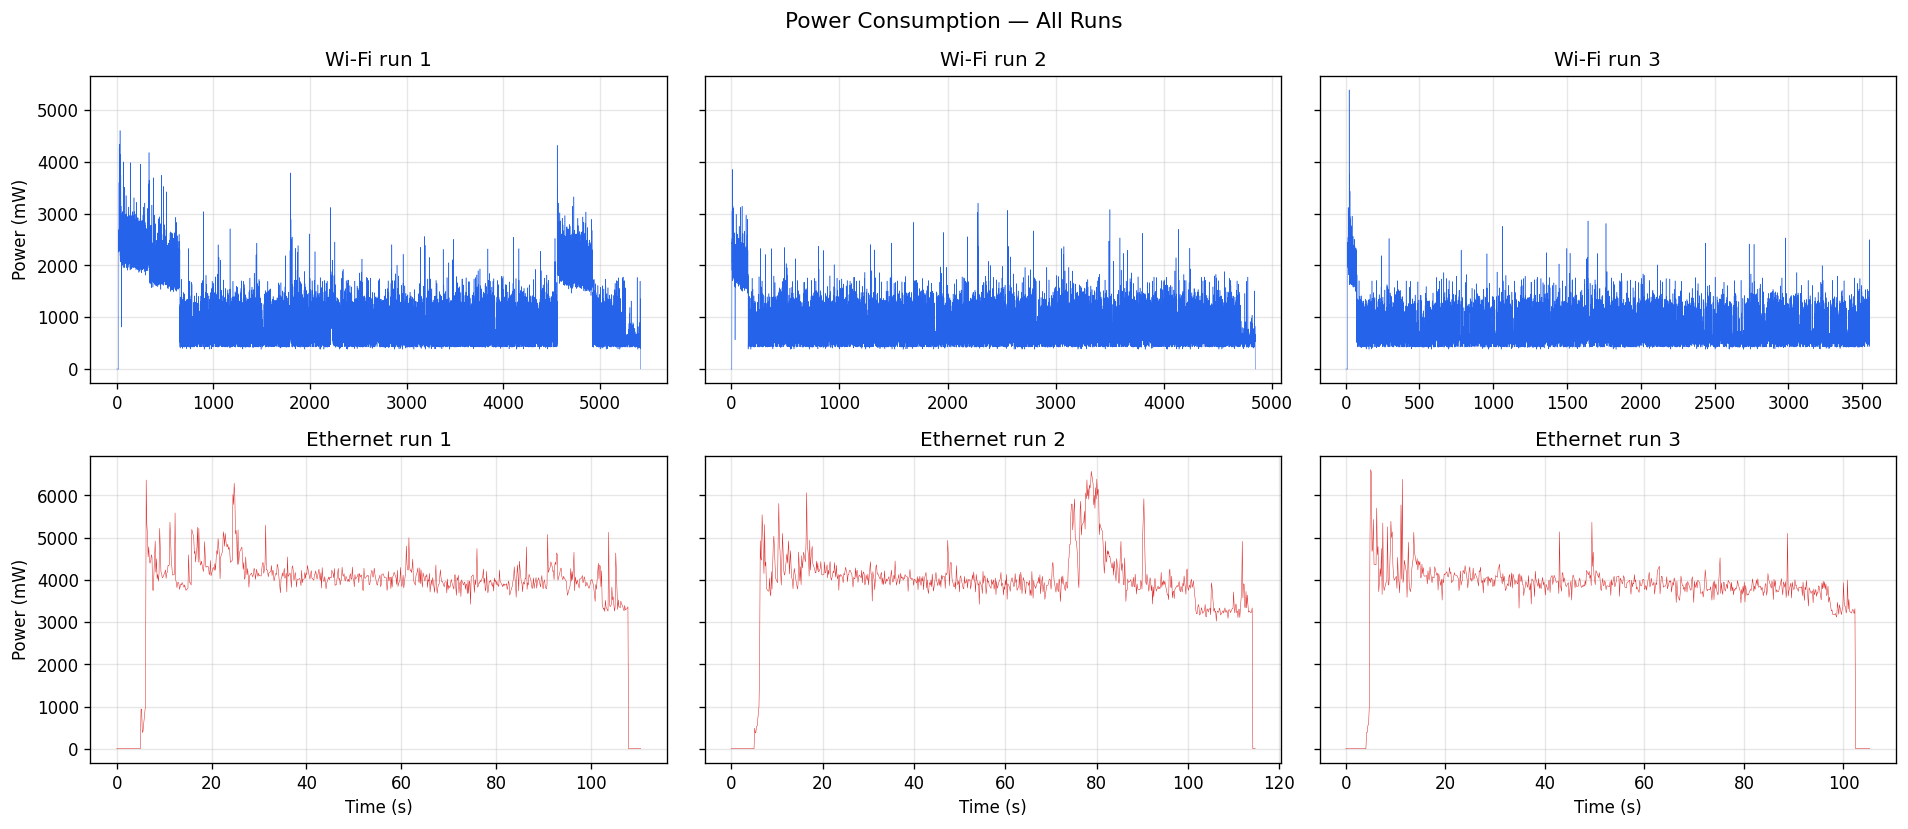

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharey='row')

for i, df in enumerate(wifi_runs):
    axes[0][i].plot(df['time_s'], df['power_mW'], linewidth=0.3, color='#2563eb')
    axes[0][i].set_title(f'Wi-Fi run {i+1}')
    axes[0][i].grid(True, alpha=0.3)
    if i == 0:
        axes[0][i].set_ylabel('Power (mW)')

for i, df in enumerate(eth_runs):
    axes[1][i].plot(df['time_s'], df['power_mW'], linewidth=0.3, color='#dc2626')
    axes[1][i].set_title(f'Ethernet run {i+1}')
    axes[1][i].set_xlabel('Time (s)')
    axes[1][i].grid(True, alpha=0.3)
    if i == 0:
        axes[1][i].set_ylabel('Power (mW)')

plt.suptitle('Power Consumption — All Runs', fontsize=13)
plt.tight_layout()
plt.savefig('all_runs.png', bbox_inches='tight')
plt.show()

## 4. Per-run statistics

In [5]:
rows = []
for i, df in enumerate(wifi_runs):
    rows.append({
        'Mode': 'Wi-Fi', 'Run': i+1,
        'Duration (s)': round(df['time_s'].iloc[-1], 1),
        'Samples': len(df),
        'Mean V': round(df['voltage_V'].mean(), 3),
        'Mean mA': round(df['current_mA'].mean(), 1),
        'Mean mW': round(df['power_mW'].mean(), 1),
        'Std mW': round(df['power_mW'].std(), 1),
        'Min mW': round(df['power_mW'].min(), 1),
        'Max mW': round(df['power_mW'].max(), 1),
        'Temp (°C)': round(df['temp_C'].mean(), 1),
        'Humidity (%)': round(df['humidity_pct'].mean(), 1),
    })
for i, df in enumerate(eth_runs):
    rows.append({
        'Mode': 'Ethernet', 'Run': i+1,
        'Duration (s)': round(df['time_s'].iloc[-1], 1),
        'Samples': len(df),
        'Mean V': round(df['voltage_V'].mean(), 3),
        'Mean mA': round(df['current_mA'].mean(), 1),
        'Mean mW': round(df['power_mW'].mean(), 1),
        'Std mW': round(df['power_mW'].std(), 1),
        'Min mW': round(df['power_mW'].min(), 1),
        'Max mW': round(df['power_mW'].max(), 1),
        'Temp (°C)': round(df['temp_C'].mean(), 1),
        'Humidity (%)': round(df['humidity_pct'].mean(), 1),
    })

stats_df = pd.DataFrame(rows)
stats_df

,Mode,Run,Duration (s),Samples,Mean V,Mean mA,Mean mW,Std mW,Min mW,Max mW,Temp (°C),Humidity (%)
0,Wi-Fi,1,5422.2,36162,5.183,180.6,936.4,581.7,0.0,4603.9,20.0,69.0
1,Wi-Fi,2,4844.9,31385,5.201,142.2,739.4,330.8,0.0,3854.6,20.0,69.0
2,Wi-Fi,3,3551.5,22725,5.190,136.2,708.7,302.4,0.0,5387.3,20.0,69.9
3,Ethernet,1,110.5,709,4.834,738.6,3770.8,1167.0,0.0,6366.8,20.0,70.8
4,Ethernet,2,114.7,736,4.880,753.7,3836.9,1114.8,0.0,6574.6,20.0,70.3
5,Ethernet,3,105.3,676,4.843,714.6,3642.3,1096.0,0.0,6612.7,20.0,70.9


## 5. Aggregated comparison: Wi-Fi vs Ethernet

In [6]:
wifi_all = pd.concat(wifi_runs, ignore_index=True)
eth_all = pd.concat(eth_runs, ignore_index=True)

summary = pd.DataFrame({
    'Wi-Fi (n=3)': {
        'Mean voltage (V)': f"{wifi_all['voltage_V'].mean():.3f}",
        'Mean current (mA)': f"{wifi_all['current_mA'].mean():.1f} ± {np.std([d['current_mA'].mean() for d in wifi_runs]):.1f}",
        'Mean power (mW)': f"{wifi_all['power_mW'].mean():.1f} ± {np.std([d['power_mW'].mean() for d in wifi_runs]):.1f}",
        'Peak power (mW)': f"{wifi_all['power_mW'].max():.1f}",
        'Mean temp (°C)': f"{wifi_all['temp_C'].mean():.1f}",
        'Mean humidity (%)': f"{wifi_all['humidity_pct'].mean():.1f}",
        'Total samples': f"{len(wifi_all)}",
    },
    'Ethernet (n=3)': {
        'Mean voltage (V)': f"{eth_all['voltage_V'].mean():.3f}",
        'Mean current (mA)': f"{eth_all['current_mA'].mean():.1f} ± {np.std([d['current_mA'].mean() for d in eth_runs]):.1f}",
        'Mean power (mW)': f"{eth_all['power_mW'].mean():.1f} ± {np.std([d['power_mW'].mean() for d in eth_runs]):.1f}",
        'Peak power (mW)': f"{eth_all['power_mW'].max():.1f}",
        'Mean temp (°C)': f"{eth_all['temp_C'].mean():.1f}",
        'Mean humidity (%)': f"{eth_all['humidity_pct'].mean():.1f}",
        'Total samples': f"{len(eth_all)}",
    }
})
summary

,Wi-Fi (n=3),Ethernet (n=3)
Mean voltage (V),5.191,4.853
Mean current (mA),156.1 ± 19.7,736.2 ± 16.1
Mean power (mW),810.6 ± 100.9,3752.8 ± 80.8
Peak power (mW),5387.3,6612.7
Mean temp (°C),20.0,20.0
Mean humidity (%),69.2,70.7
Total samples,90272,2121


## 6. Box plot comparison

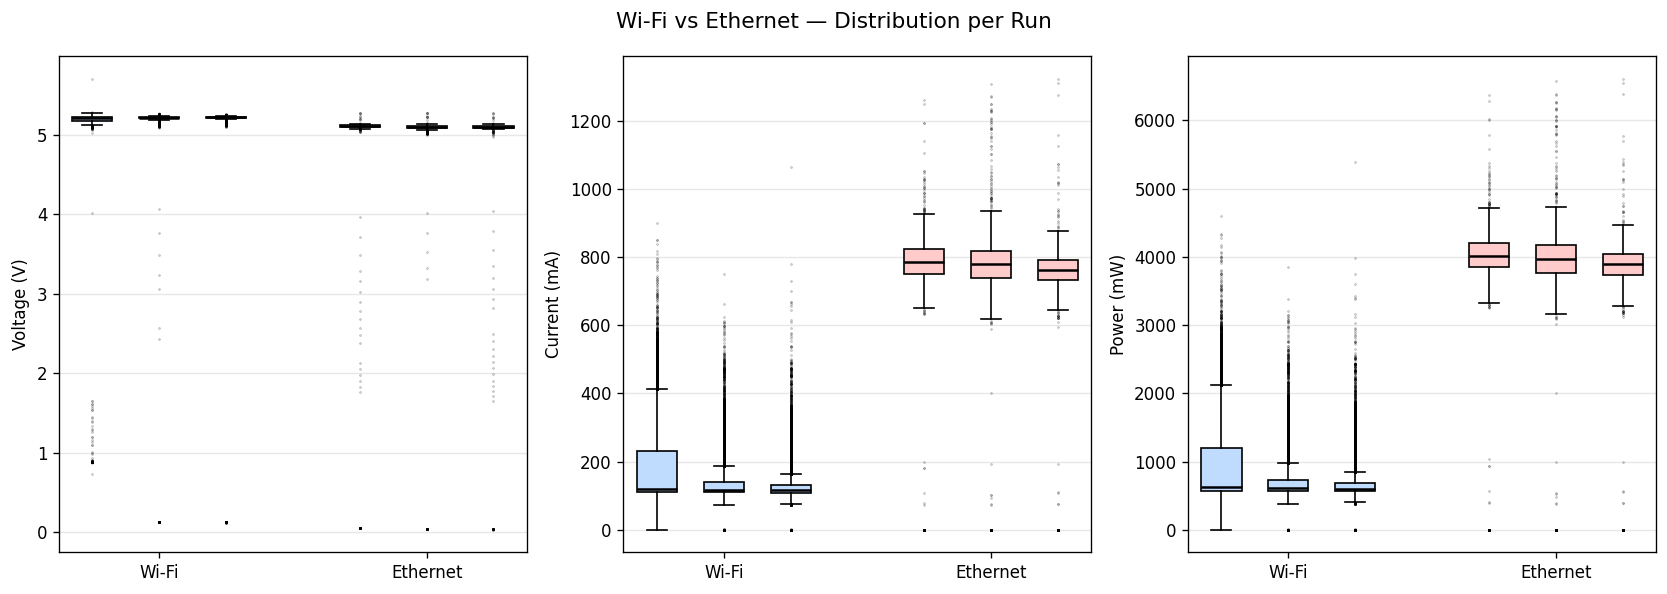

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, metric, unit in zip(axes, ['voltage_V', 'current_mA', 'power_mW'], ['V', 'mA', 'mW']):
    wifi_data = [d[metric] for d in wifi_runs]
    eth_data = [d[metric] for d in eth_runs]

    positions = [1, 2, 3, 5, 6, 7]
    bp = ax.boxplot(
        wifi_data + eth_data,
        positions=positions,
        widths=0.6,
        patch_artist=True,
        medianprops=dict(color='black', linewidth=1.5),
        flierprops=dict(marker='.', markersize=1, alpha=0.3),
    )
    for i, box in enumerate(bp['boxes']):
        box.set_facecolor('#bfdbfe' if i < 3 else '#fecaca')

    ax.set_xticks([2, 6])
    ax.set_xticklabels(['Wi-Fi', 'Ethernet'])
    ax.set_ylabel(f'{metric.split("_")[0].title()} ({unit})')
    ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Wi-Fi vs Ethernet — Distribution per Run', fontsize=13)
plt.tight_layout()
plt.savefig('boxplot_comparison.png', bbox_inches='tight')
plt.show()

## 7. Overlaid power curves

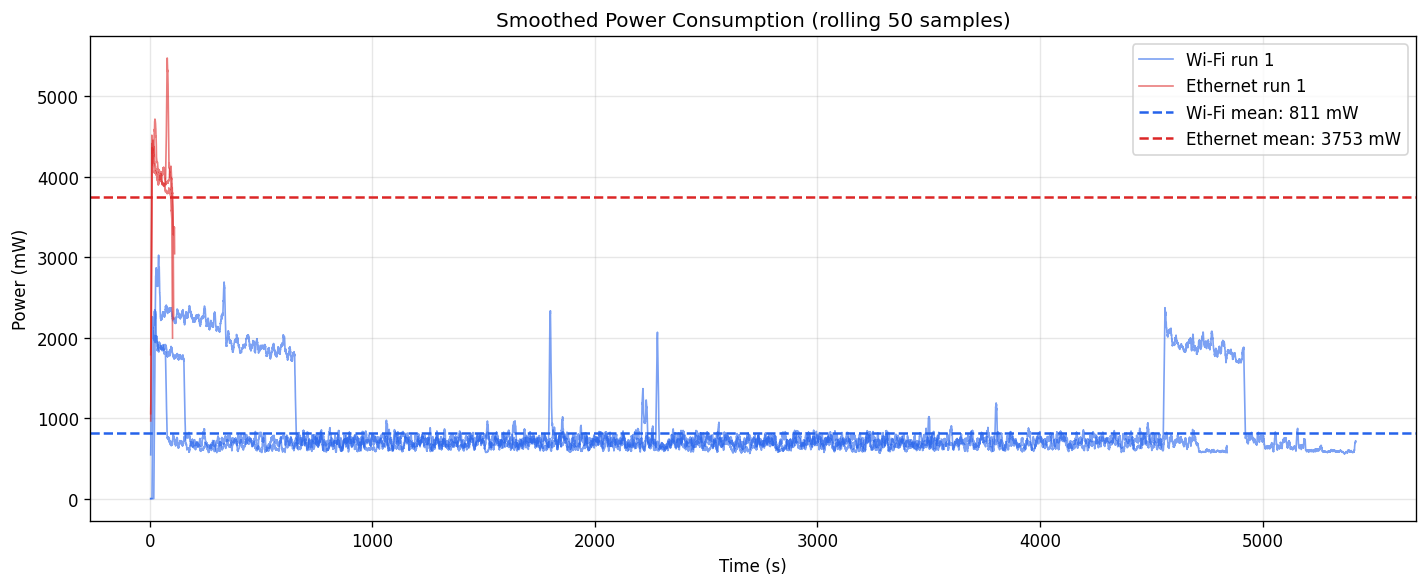

In [8]:
WINDOW = 50  # rolling average window (~5s at 100ms)

fig, ax = plt.subplots(figsize=(12, 5))

for i, df in enumerate(wifi_runs):
    smoothed = df['power_mW'].rolling(WINDOW, center=True).mean()
    ax.plot(df['time_s'], smoothed, linewidth=1, color='#2563eb',
            alpha=0.6, label=f'Wi-Fi run {i+1}' if i == 0 else '_')

for i, df in enumerate(eth_runs):
    smoothed = df['power_mW'].rolling(WINDOW, center=True).mean()
    ax.plot(df['time_s'], smoothed, linewidth=1, color='#dc2626',
            alpha=0.6, label=f'Ethernet run {i+1}' if i == 0 else '_')

# Add mean lines
wifi_mean = wifi_all['power_mW'].mean()
eth_mean = eth_all['power_mW'].mean()
ax.axhline(wifi_mean, color='#2563eb', linestyle='--', linewidth=1.5,
           label=f'Wi-Fi mean: {wifi_mean:.0f} mW')
ax.axhline(eth_mean, color='#dc2626', linestyle='--', linewidth=1.5,
           label=f'Ethernet mean: {eth_mean:.0f} mW')

ax.set_xlabel('Time (s)')
ax.set_ylabel('Power (mW)')
ax.set_title(f'Smoothed Power Consumption (rolling {WINDOW} samples)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('overlay_comparison.png', bbox_inches='tight')
plt.show()

## 8. Ambient conditions across all runs

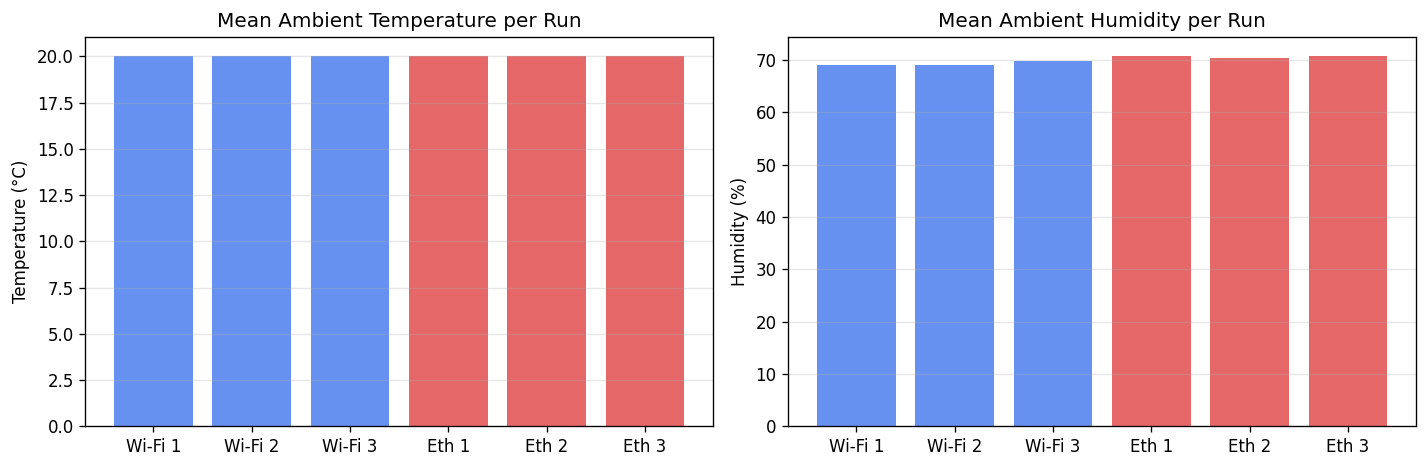

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

all_runs = wifi_runs + eth_runs
all_labels = [f'Wi-Fi {i+1}' for i in range(3)] + [f'Eth {i+1}' for i in range(3)]
all_colors = ['#2563eb']*3 + ['#dc2626']*3

temps = [df['temp_C'].mean() for df in all_runs]
hums = [df['humidity_pct'].mean() for df in all_runs]

axes[0].bar(all_labels, temps, color=all_colors, alpha=0.7)
axes[0].set_ylabel('Temperature (°C)')
axes[0].set_title('Mean Ambient Temperature per Run')
axes[0].grid(True, alpha=0.3, axis='y')

axes[1].bar(all_labels, hums, color=all_colors, alpha=0.7)
axes[1].set_ylabel('Humidity (%)')
axes[1].set_title('Mean Ambient Humidity per Run')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('ambient.png', bbox_inches='tight')
plt.show()

## 9. Export all figures

In [10]:
import glob
for f in glob.glob('*.png'):
    files.download(f)
    print(f'Downloaded: {f}')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: overlay_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Downloaded: boxplot_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: all_runs.png
